
---
date: "2026-09-13"
date-modified: last-modified
format:
  html:
    toc: true
---



# Subspaces, Sums, and Span

**Prerequisites:** [Vector Spaces](vector-spaces.ipynb)

Most vector spaces met in practice live inside a bigger one: a plane through the origin inside $\mathbb{R}^3$, the polynomials inside all functions, the solutions of a homogeneous system inside $K^n$. Such a subset is a **subspace**. This note introduces subspaces, the two basic ways to combine them (intersection and sum), and the subspace **spanned** by a set of vectors.

Throughout, $V$ is a [vector space](vector-spaces.ipynb) over a field $K$.

## 1\. Subspaces

::: {#def-subspace}
## Subspace

A subset $W \subseteq V$ is a **(linear) subspace** of $V$ if $W$ is non-empty and, with the addition and scalar multiplication of $V$ restricted to $W$, is itself a vector space over $K$. We write $W \le V$.
:::

Checking eight axioms every time would be tedious. Most of them hold automatically in $W$ because they hold in $V$; only closure needs checking.

::: {#prp-subspace-criterion}
## Subspace Criterion

A subset $W \subseteq V$ is a subspace if and only if

1. $W \neq \emptyset$,
2. $u + v \in W$ for all $u, v \in W$ (closed under addition), and
3. $a v \in W$ for all $a \in K$ and $v \in W$ (closed under scalar multiplication).

Equivalently: $0 \in W$, and $a u + v \in W$ for all $a \in K$ and $u, v \in W$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-subspace-criterion
($\Rightarrow$) A subspace is a vector space under the restricted operations, so these operations must take values in $W$; and a vector space is non-empty.

($\Leftarrow$) Conditions 2 and 3 say that the operations of $V$ restrict to operations on $W$. Axioms 1, 2 and 5 to 8 of a [vector space](vector-spaces.ipynb#def-vector-space) are identities that hold for all elements of $V$, hence in particular for elements of $W$. It remains to find a zero vector and inverses inside $W$. Pick any $w \in W$ (possible by condition 1). By the [basic rules](vector-spaces.ipynb#prp-vector-space-consequences), $0 = 0 \cdot w \in W$ and, for every $v \in W$, $-v = (-1)\,v \in W$.

For the equivalent form: if $W$ is a subspace, then $0 \in W$ and $au + v \in W$. Conversely, if $0 \in W$ and $au + v \in W$ always, then $W \neq \emptyset$, taking $a = 1$ gives closure under addition, and taking $v = 0$ gives closure under scalar multiplication. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Subspaces Pass Through the Origin
Every subspace contains $0$. In $\mathbb{R}^2$ the subspaces are exactly $\{0\}$, the lines through the origin, and $\mathbb{R}^2$ itself; in $\mathbb{R}^3$ one adds the planes through the origin. A line or plane that misses the origin is never a subspace.
:::

::: {#exm-subspaces}
## Subspaces in Practice

1. **Solutions of a homogeneous linear system.** $W = \{(x, y, z) \in \mathbb{R}^3 \mid x + y + z = 0\}$ is a subspace: $0 \in W$, and if $x + y + z = 0$ and $x' + y' + z' = 0$ then $(ax + x') + (ay + y') + (az + z') = a \cdot 0 + 0 = 0$. The same argument works for the solutions of any system of homogeneous linear equations.
2. **Polynomials vanishing at a point.** $\{p \in P_d \mid p(1) = 0\}$ is a subspace of $P_d$, because $(ap + q)(1) = a\,p(1) + q(1)$.
3. **Even functions.** $\{f : \mathbb{R} \to \mathbb{R} \mid f(-x) = f(x) \text{ for all } x\}$ is a subspace of $\mathbb{R}^{\mathbb{R}}$.
4. **Continuous functions** $C([a, b])$ form a subspace of $\mathbb{R}^{[a,b]}$; differentiable functions form a subspace of $C([a, b])$.
:::

::: {.callout-warning}
## Three Sets That Are Not Subspaces
In $\mathbb{R}^2$:

- the line $y = x + 1$ misses $0$;
- the union of the two coordinate axes is closed under scalar multiplication but not under addition: $(1, 0) + (0, 1) = (1, 1)$ lies on neither axis;
- the closed first quadrant $\{x \ge 0, y \ge 0\}$ is closed under addition but not under multiplication by $-1$.

Each condition of the criterion is really needed.
:::


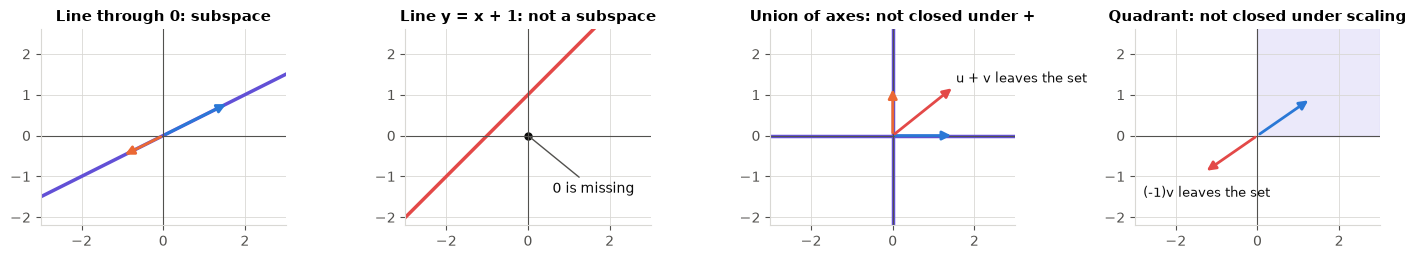

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
VIOLET, RED = "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10})

def arrow(ax, v, color, origin=(0, 0)):
    ax.annotate("", xy=(origin[0] + v[0], origin[1] + v[1]), xytext=origin,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=13))

t = np.linspace(-3, 3, 2)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.7))

ax = axes[0]
ax.plot(t, 0.5 * t, color=VIOLET, lw=2.5)
arrow(ax, (1.6, 0.8), BLUE); arrow(ax, (-1.0, -0.5), ORANGE)
ax.set_title("Line through 0: subspace")

ax = axes[1]
ax.plot(t, t + 1, color=RED, lw=2.5)
ax.plot(0, 0, "o", color=INK, ms=5)
ax.annotate("0 is missing", (0, 0), (0.6, -1.4), color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_title("Line y = x + 1: not a subspace")

ax = axes[2]
ax.plot(t, 0 * t, color=VIOLET, lw=2.5); ax.plot(0 * t, t, color=VIOLET, lw=2.5)
arrow(ax, (1.5, 0), BLUE); arrow(ax, (0, 1.2), ORANGE); arrow(ax, (1.5, 1.2), RED)
ax.text(1.55, 1.3, "u + v leaves the set", color=INK, fontsize=9)
ax.set_title("Union of axes: not closed under +")

ax = axes[3]
ax.fill([0, 3, 3, 0], [0, 0, 3, 3], color=VIOLET, alpha=0.12)
arrow(ax, (1.3, 0.9), BLUE); arrow(ax, (-1.3, -0.9), RED)
ax.text(-2.8, -1.5, "(-1)v leaves the set", color=INK, fontsize=9)
ax.set_title("Quadrant: not closed under scaling")

for ax in axes:
    ax.set_aspect("equal"); ax.set_xlim(-3, 3); ax.set_ylim(-2.2, 2.6)
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
plt.tight_layout(); plt.show()



## 2\. Intersections and Sums of Subspaces

### 2\.1\. Intersection

::: {#prp-intersection-subspace}
## Intersections of Subspaces

The intersection of any (finite or infinite) family of subspaces of $V$ is a subspace of $V$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-intersection-subspace
Let $(W_i)_{i \in I}$ be subspaces and $W = \bigcap_{i \in I} W_i$. Each $W_i$ contains $0$, so $0 \in W$. If $u, v \in W$ and $a \in K$, then $u, v \in W_i$ for every $i$, so $au + v \in W_i$ for every $i$, that is, $au + v \in W$. By the [criterion](#prp-subspace-criterion), $W$ is a subspace. $\blacksquare$
:::

The **union** of two subspaces is usually not a subspace: the coordinate axes above are an example. In fact $W_1 \cup W_2$ is a subspace only when one of them contains the other.

### 2\.2\. Sum

Since the union is too small, we enlarge it to the smallest set that is closed under addition.

::: {#def-sum-subspaces}
## Sum of Subspaces

For subspaces $W_1, W_2 \le V$, their **sum** is

$$W_1 + W_2 = \{w_1 + w_2 \mid w_1 \in W_1,\ w_2 \in W_2\}.$$

More generally, $W_1 + \dots + W_s = \{w_1 + \dots + w_s \mid w_i \in W_i\}$.
:::

::: {#prp-sum-is-subspace}
## The Sum Is a Subspace

$W_1 + W_2$ is a subspace of $V$. It contains $W_1$ and $W_2$, and it is contained in every subspace that contains both $W_1$ and $W_2$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-sum-is-subspace
$0 = 0 + 0 \in W_1 + W_2$. For $x = w_1 + w_2$ and $x' = w_1' + w_2'$ in $W_1 + W_2$ and $a \in K$, commutativity, associativity and distributivity give
$$a x + x' = (a w_1 + w_1') + (a w_2 + w_2'),$$
where $a w_1 + w_1' \in W_1$ and $a w_2 + w_2' \in W_2$ because these are subspaces. So $W_1 + W_2$ is a subspace.

Every $w_1 \in W_1$ equals $w_1 + 0$ with $0 \in W_2$, so $W_1 \subseteq W_1 + W_2$; similarly $W_2 \subseteq W_1 + W_2$. If $U$ is a subspace containing $W_1$ and $W_2$, then $U$ contains every sum $w_1 + w_2$ by closure under addition, so $W_1 + W_2 \subseteq U$. $\blacksquare$
:::

::: {#exm-two-lines}
## Two Lines in the Plane and in Space

Let $W_1 = \{(t, 0, 0)\}$ and $W_2 = \{(0, t, 0)\}$ be the $x$- and $y$-axes in $\mathbb{R}^3$. Then $W_1 \cap W_2 = \{0\}$, the union $W_1 \cup W_2$ is two lines (not a subspace), and $W_1 + W_2 = \{(s, t, 0)\}$ is the whole $xy$-plane. If instead $W_2 = W_1$, then $W_1 + W_2 = W_1$.
:::

## 3\. Linear Combinations and Span

::: {#def-linear-combination}
## Linear Combination

A **linear combination** of vectors $v_1, \dots, v_k \in V$ is a vector of the form

$$c_1 v_1 + c_2 v_2 + \dots + c_k v_k \qquad (c_1, \dots, c_k \in K).$$

The scalars $c_i$ are its **coefficients**. By convention, the empty linear combination ($k = 0$) is $0$.
:::

::: {#def-span}
## Span

The **span** of a subset $S \subseteq V$ is the set of all linear combinations of finitely many elements of $S$:

$$\operatorname{span}(S) = \{c_1 v_1 + \dots + c_k v_k \mid k \ge 0,\ v_i \in S,\ c_i \in K\}.$$

For $S = \{v_1, \dots, v_k\}$ we write $\operatorname{span}(v_1, \dots, v_k)$. If $\operatorname{span}(S) = V$ we say that $S$ **spans** (or **generates**) $V$. In particular $\operatorname{span}(\emptyset) = \{0\}$.
:::

::: {#prp-span-is-subspace}
## The Span Is the Smallest Subspace Containing $S$

$\operatorname{span}(S)$ is a subspace of $V$ that contains $S$, and every subspace containing $S$ contains $\operatorname{span}(S)$. Consequently
$$\operatorname{span}(S) = \bigcap \{W \le V \mid S \subseteq W\}.$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-span-is-subspace
**Subspace.** The empty combination gives $0 \in \operatorname{span}(S)$. Two linear combinations $x = \sum_i c_i v_i$ and $y = \sum_i d_i v_i$ can be written over the same finite list $v_1, \dots, v_k$ of elements of $S$ (add missing vectors with coefficient $0$). Then
$$a x + y = \sum_{i=1}^k (a c_i + d_i)\, v_i \in \operatorname{span}(S).$$

**Contains $S$.** Each $v \in S$ equals $1 \cdot v$.

**Smallest.** A subspace $W \supseteq S$ is closed under addition and scalar multiplication, so it contains every linear combination of elements of $S$.

The last statement follows: $\operatorname{span}(S)$ is one of the subspaces in the intersection, so the intersection is contained in it, and it is contained in each of them, hence in the intersection. $\blacksquare$
:::

::: {.callout-note}
## Span and Sum
For subspaces, $W_1 + W_2 = \operatorname{span}(W_1 \cup W_2)$, because both are the smallest subspace containing $W_1$ and $W_2$. For two non-collinear vectors $u, v$ in a plane, $\operatorname{span}(u) + \operatorname{span}(v) = \operatorname{span}(u, v)$ is the whole plane.

Even if $S$ is infinite, each element of $\operatorname{span}(S)$ uses only **finitely many** vectors of $S$. For instance, $\operatorname{span}(1, x, x^2, \dots) = \mathbb{R}[x]$ consists of polynomials, not power series.
:::

The animation shows the combinations $w = a u + b v$ as the coefficients vary. When $u$ and $v$ point in different directions, the tip of $w$ can reach every point of the plane. The violet lines are the lines $k u + t v$ and $k v + t u$ for integers $k$: the grid that $u$ and $v$ draw on the plane. When $v$ is moved onto the line of $u$, this grid collapses onto that line and every combination stays on it: the span shrinks from a plane to a line.


In [2]:

from la_manim import *

class SpanOfTwoVectors(GridScene):
    def construct(self):
        self.plane.set_stroke(opacity=0.18)           # nothing is transformed here: keep the grid quiet
        u = np.array([2.0, 0.5, 0.0])
        vx, vy = ValueTracker(0.6), ValueTracker(1.5)
        a, b = ValueTracker(1.0), ValueTracker(1.0)
        V = lambda: np.array([vx.get_value(), vy.get_value(), 0.0])
        W = lambda: a.get_value() * u + b.get_value() * V()
        style = dict(buff=0, stroke_width=5, max_tip_length_to_length_ratio=0.2, tip_length=0.22)

        u_arrow = Arrow(ORIGIN, u, color=C_BLUE, **style)
        v_arrow = always_redraw(lambda: Arrow(ORIGIN, V(), color=C_ORANGE, **style))
        au = always_redraw(lambda: DashedLine(ORIGIN, a.get_value() * u, color=C_BLUE, stroke_width=2.5))
        bv = always_redraw(lambda: DashedLine(a.get_value() * u, W(), color=C_ORANGE, stroke_width=2.5))
        w_arrow = always_redraw(lambda: Arrow(ORIGIN, W(), color=C_YELLOW, **style))
        u_lab = MathTex("u", color=C_BLUE).next_to(u, DR, buff=0.1)
        v_lab = always_redraw(lambda: MathTex("v", color=C_ORANGE).next_to(V(), UL, buff=0.1))
        w_lab = always_redraw(lambda: MathTex("w", color=C_YELLOW).next_to(W(), UR, buff=0.08))

        coeffs = VGroup(MathTex("w = a\\,u + b\\,v", color=C_INK),
                        VGroup(MathTex("a =", color=C_INK), DecimalNumber(1.0, num_decimal_places=1, color=C_BLUE)).arrange(RIGHT),
                        VGroup(MathTex("b =", color=C_INK), DecimalNumber(1.0, num_decimal_places=1, color=C_ORANGE)).arrange(RIGHT)
                        ).arrange(DOWN, aligned_edge=LEFT).scale(0.7).to_corner(UL, buff=0.3)
        coeffs[1][1].add_updater(lambda m: m.set_value(a.get_value()))
        coeffs[2][1].add_updater(lambda m: m.set_value(b.get_value()))
        box = BackgroundRectangle(coeffs, fill_opacity=0.85, buff=0.15, color=config.background_color)

        def skew_grid():
            # the lines k*u + t*v and k*v + t*u: the "coordinate grid" made by u and v
            d = V()
            lines = VGroup(*[Line(k * u - 8 * d, k * u + 8 * d) for k in range(-6, 7)],
                           *[Line(k * d - 8 * u, k * d + 8 * u) for k in range(-12, 13)])
            return lines.set_stroke(C_VIOLET, width=1.6, opacity=0.7)
        grid = always_redraw(skew_grid)
        self.add(au, bv, u_arrow, v_arrow, w_arrow, u_lab, v_lab, w_lab, box, coeffs)
        self.wait(0.5)
        self.play(FadeIn(grid), run_time=1.5)

        # independent u, v: the combinations sweep out the plane
        for av, bv_ in [(-1.2, 1.4), (-1.6, -1.2), (0.8, -1.6), (1.8, 0.4), (0.2, 1.8), (-0.6, -0.4), (1.0, 1.0)]:
            self.play(a.animate.set_value(av), b.animate.set_value(bv_), run_time=1.0, rate_func=smooth)
        msg = text_caption(r"$u, v$ independent: $\operatorname{span}(u,v)$ is the whole plane")
        self.play(FadeIn(msg)); self.wait(1)

        # make v a multiple of u: the span collapses to a line
        line = Line(-4 * u, 4 * u, color=C_VIOLET, stroke_width=3)
        self.play(FadeOut(msg))
        self.play(vx.animate.set_value(-1.0), vy.animate.set_value(-0.25), run_time=3)
        self.play(Create(line))
        for av, bv_ in [(1.5, -1.5), (-1.0, 1.0), (0.5, 2.0), (1.6, 0.4)]:
            self.play(a.animate.set_value(av), b.animate.set_value(bv_), run_time=1.0)
        msg2 = text_caption(r"$v = -\tfrac12 u$: every $a u + b v$ lies on one line")
        self.play(FadeIn(msg2)); self.wait(1.5)

show(SpanOfTwoVectors)
